# 01 – Data Exploration & Preprocessing (Milestone 1)
**Project:** AI-Based Credit Card Fraud Detection | **Course:** INSE 6450

Runs end to end in Google Colab: *Runtime → Run all*.

## 1. Import libraries

In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

#saved outputs folder
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

## 2. Download the train / test data from Kaggle
Dataset: [kartik2112/fraud-detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection)


In [2]:
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

def download_data():
    """Download the dataset and copy the train/test CSVs into the current folder."""
    path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
    for name in ("fraudTrain.csv", "fraudTest.csv"):
        shutil.copy(next(path.rglob(name)), name)

if not (os.path.exists("fraudTrain.csv") and os.path.exists("fraudTest.csv")):
    try:
        download_data()
    except Exception as e:
        print("Anonymous download failed:", e)
        print("Please log in to Kaggle below, then the download will retry.")
        kagglehub.login()
        download_data()

print("CSV files:", [f for f in os.listdir(".") if f.endswith(".csv")])

100%|██████████| 202M/202M [00:11<00:00, 18.2MB/s]

Extracting files...


CSV files: ['fraudTrain.csv', 'fraudTest.csv']


## 3. Load the data and check what it contains

In [3]:
train_df = pd.read_csv("fraudTrain.csv")
test_df = pd.read_csv("fraudTest.csv")

train_df = train_df.drop(columns=["Unnamed: 0"], errors="ignore")
test_df = test_df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Number of original features:", train_df.shape[1] - 1)

Train shape: (1296675, 22)
Test shape: (555719, 22)
Number of original features: 21


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  object 
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  object 
 3   category               1296675 non-null  object 
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  object 
 6   last                   1296675 non-null  object 
 7   gender                 1296675 non-null  object 
 8   street                 1296675 non-null  object 
 9   city                   1296675 non-null  object 
 10  state                  1296675 non-null  object 
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop          

In [5]:
train_df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
print(train_df.columns)

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud'],
      dtype='object')


In [7]:
train_df.describe()

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


## 4. Data quality: missing values and duplicates

In [8]:
missing_values = train_df.isnull().sum()
missing_values = missing_values[missing_values > 0]
print("Missing values per column:")
print(missing_values if len(missing_values) else "None")

print("\nDuplicate rows (train):", train_df.duplicated().sum())
print("Duplicate transaction ids (train):", train_df["trans_num"].duplicated().sum())

Missing values per column:
None

Duplicate rows (train): 0
Duplicate transaction ids (train): 0


In [9]:
train_df[["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]].describe()

,amt,city_pop,lat,long,merch_lat,merch_long
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,7.035104e+01,8.882444e+04,3.853762e+01,-9.022634e+01,3.853734e+01,-9.022646e+01
std,1.603160e+02,3.019564e+05,5.075808e+00,1.375908e+01,5.109788e+00,1.377109e+01
min,1.000000e+00,2.300000e+01,2.002710e+01,-1.656723e+02,1.902779e+01,-1.666712e+02
25%,9.650000e+00,7.430000e+02,3.462050e+01,-9.679800e+01,3.473357e+01,-9.689728e+01
50%,4.752000e+01,2.456000e+03,3.935430e+01,-8.747690e+01,3.936568e+01,-8.743839e+01
75%,8.314000e+01,2.032800e+04,4.194040e+01,-8.015800e+01,4.195716e+01,-8.023680e+01
max,2.894890e+04,2.906700e+06,6.669330e+01,-6.795030e+01,6.751027e+01,-6.695090e+01


In [10]:
duplicate_rows = train_df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


## 5. Class distribution


In [11]:
train_counts = train_df["is_fraud"].value_counts().sort_index()
test_counts = test_df["is_fraud"].value_counts().sort_index()

summary = pd.DataFrame({
    "train_count": train_counts, "train_%": (train_counts / train_counts.sum() * 100).round(3),
    "test_count": test_counts,   "test_%": (test_counts / test_counts.sum() * 100).round(3),
})
summary.index = ["Legitimate (0)", "Fraud (1)"]
print(summary)
print(f"\nImbalance ratio (train): {train_counts[0] / train_counts[1]:.0f} : 1")

                train_count  train_%  test_count  test_%
Legitimate (0)      1289169   99.421      553574  99.614
Fraud (1)              7506    0.579        2145   0.386

Imbalance ratio (train): 172 : 1


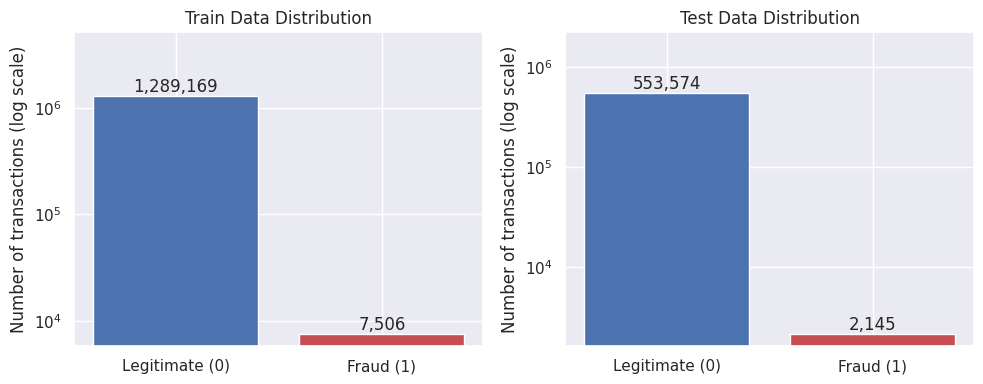

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, counts, title in zip(axes, (train_counts, test_counts), ("Train", "Test")):
    bars = ax.bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=["#4c72b0", "#c44e52"])
    ax.set_yscale("log")
    ax.set_ylim(top=counts.max() * 4)
    ax.set_title(f"{title} Data Distribution")
    ax.set_ylabel("Number of transactions (log scale)")
    for b, v in zip(bars, counts.values):
        ax.annotate(f"{v:,}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom")
plt.tight_layout()

plt.savefig("outputs/figures/class_distribution.pdf", bbox_inches="tight")
plt.savefig("outputs/figures/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Fraud patterns

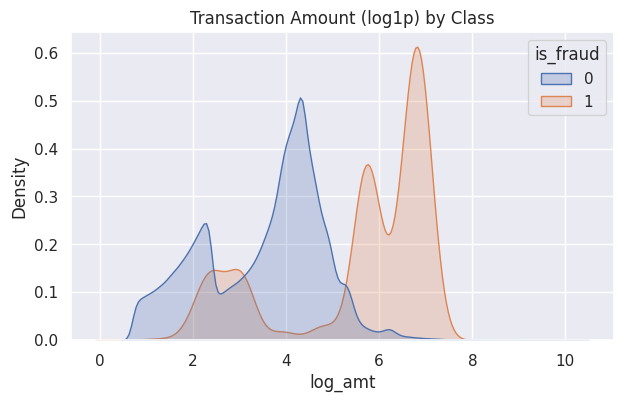

In [12]:
plt.figure(figsize=(7, 4))
sns.kdeplot(data=train_df.assign(log_amt=np.log1p(train_df["amt"])),
            x="log_amt", hue="is_fraud", common_norm=False, fill=True)
plt.title("Transaction Amount (log1p) by Class")
plt.savefig("outputs/figures/amount_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

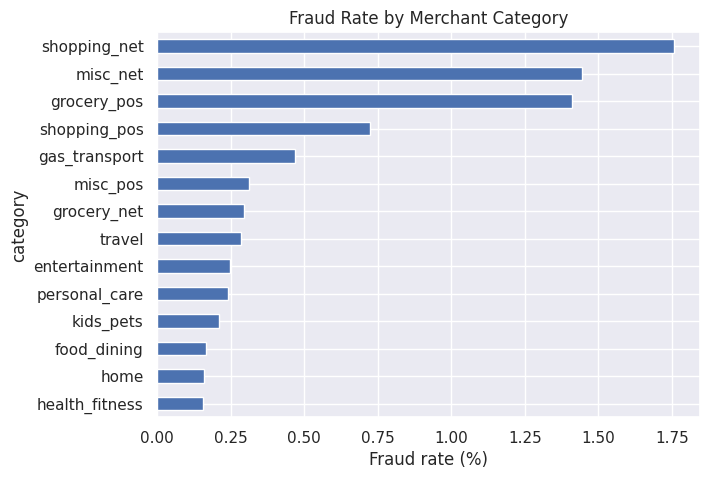

In [21]:
rate = train_df.groupby("category")["is_fraud"].mean().sort_values() * 100

plt.figure(figsize=(7, 5))
rate.plot(kind="barh")
plt.xlabel("Fraud rate (%)")
plt.title("Fraud Rate by Merchant Category")
plt.savefig("outputs/figures/fraud_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Outlier check (IQR rule)

In [13]:
numeric_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
outlier_summary = {}

for col in numeric_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = train_df[(train_df[col] < Q1 - 1.5 * IQR) | (train_df[col] > Q3 + 1.5 * IQR)]
    outlier_summary[col] = len(outliers)

print("Outlier count (IQR rule):")
print(outlier_summary)

Outlier count (IQR rule):
{'amt': 67290, 'city_pop': 242674, 'lat': 4679, 'long': 49922, 'merch_lat': 4967, 'merch_long': 41994}


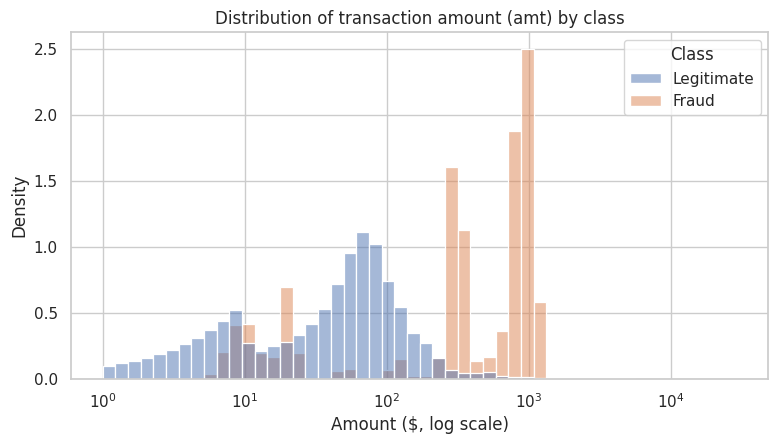

In [14]:
plot_df = train_df.copy()
plot_df["Class"] = plot_df["is_fraud"].map({0: "Legitimate", 1: "Fraud"})

with sns.axes_style("whitegrid"):
    plt.figure(figsize=(9, 4.5))
    sns.histplot(
        data=plot_df, x="amt", hue="Class",
        hue_order=["Legitimate", "Fraud"],
        bins=50, log_scale=True,
        stat="density",
        common_norm=False,
    )
    plt.title("Distribution of transaction amount (amt) by class")
    plt.xlabel("Amount ($, log scale)")
    plt.ylabel("Density")
    plt.savefig("outputs/figures/amount_histogram.png", dpi=300, bbox_inches="tight")
    plt.show()

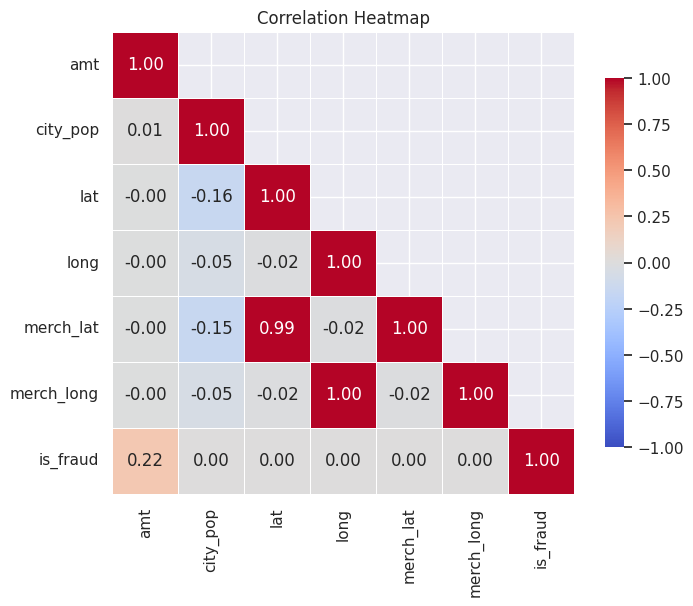

In [13]:
raw_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long", "is_fraud"]
corr_raw = train_df[raw_cols].corr()

mask = np.triu(np.ones_like(corr_raw, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_raw, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap")
plt.savefig("outputs/figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.savefig("outputs/figures/correlation_heatmap.pdf", bbox_inches="tight")
plt.show()

In [14]:
def clean(df):
    df = df.copy()
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])
    df = df.drop_duplicates(subset="trans_num").dropna()
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)

train_clean = clean(train_df)
test_clean = clean(test_df)
print("After cleaning -> train:", train_clean.shape, "| test:", test_clean.shape)

After cleaning -> train: (1296675, 22) | test: (555719, 22)


In [15]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distance in km between customer home and merchant."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def build_features(df):
    ts = df["trans_date_trans_time"]
    out = pd.DataFrame(index=df.index)

    # Time features
    out["hour"] = ts.dt.hour
    out["day_of_week"] = ts.dt.dayofweek
    out["month"] = ts.dt.month
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["is_night"] = ((out["hour"] >= 22) | (out["hour"] <= 3)).astype(int)

    # Customer / transaction features
    out["age"] = (ts - df["dob"]).dt.days / 365.25
    out["gender_male"] = (df["gender"] == "M").astype(int)
    out["log_amt"] = np.log1p(df["amt"])
    out["log_city_pop"] = np.log1p(df["city_pop"])

    # Geographic feature
    out["distance_km"] = haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

    out["category"] = df["category"].values
    out["is_fraud"] = df["is_fraud"].values
    return out

train_feat = build_features(train_clean)
test_feat = build_features(test_clean)

dropped = [c for c in train_clean.columns if c not in ("category", "is_fraud")]
print("Raw columns replaced by engineered features / dropped:", len(dropped))
train_feat.head()

Raw columns replaced by engineered features / dropped: 20


,hour,day_of_week,month,is_weekend,is_night,age,gender_male,log_amt,log_city_pop,distance_km,category,is_fraud
0,0,1,1,0,1,30.814511,0,1.786747,8.159375,78.597568,misc_net,0
1,0,1,1,0,1,40.531143,0,4.684259,5.010635,30.212176,grocery_pos,0
2,0,1,1,0,1,56.950034,1,5.398660,8.332068,108.206083,entertainment,0
3,0,1,1,0,1,51.969884,1,3.828641,7.570443,95.673231,gas_transport,0
4,0,1,1,0,1,32.763860,1,3.760269,4.605170,77.556744,misc_pos,0


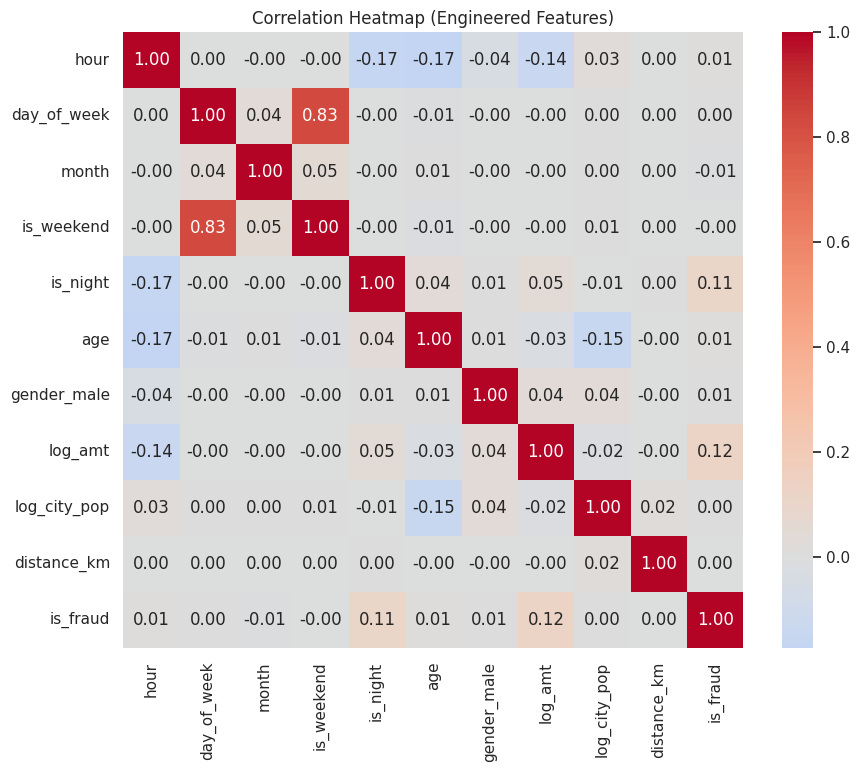

Correlation with is_fraud:
log_amt         0.120
is_night        0.110
hour            0.014
month          -0.012
age             0.012
gender_male     0.008
is_weekend     -0.004
day_of_week     0.002
log_city_pop    0.002
distance_km     0.000
Name: is_fraud, dtype: float64


In [16]:
num_cols = [c for c in train_feat.columns if c != "category"]
corr = train_feat[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Engineered Features)")

plt.savefig("outputs/figures/correlation_heatmap.pdf", bbox_inches="tight")
plt.savefig("outputs/figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Correlation with is_fraud:")
print(corr["is_fraud"].drop("is_fraud").sort_values(key=abs, ascending=False).round(3))

In [17]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nMissing percentage:")
print((train_df.isnull().mean() * 100).round(2))

Missing values:
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

Missing percentage:
trans_date_trans_time    0.0
cc_num                   0.0
merchant                 0.0
category                 0.0
amt                      0.0
first                    0.0
last                     0.0
gender                   0.0
street                   0.0
city                     0.0
state                    0.0
zip                      0.0
lat     

In [18]:
train_enc = pd.get_dummies(train_feat, columns=["category"], prefix="cat", dtype=int)
test_enc = pd.get_dummies(test_feat, columns=["category"], prefix="cat", dtype=int)
test_enc = test_enc.reindex(columns=train_enc.columns, fill_value=0)

scale_cols = ["hour", "day_of_week", "month", "age", "log_amt", "log_city_pop", "distance_km"]
scaler = StandardScaler()
train_enc[scale_cols] = scaler.fit_transform(train_enc[scale_cols])
test_enc[scale_cols] = scaler.transform(test_enc[scale_cols])

X_train_scaled = train_enc.drop(columns=["is_fraud"])
X_test_scaled = test_enc.drop(columns=["is_fraud"])
y_train = train_enc["is_fraud"].to_numpy()
y_test = test_enc["is_fraud"].to_numpy()

print("Feature shape:", X_train_scaled.shape)
print("Label shape:", y_train.shape)
print("Features:", list(X_train_scaled.columns))

train_enc.to_csv("data/processed/train_processed.csv", index=False)
test_enc.to_csv("data/processed/test_processed.csv", index=False)
X_train_scaled.head()

Feature shape: (1296675, 24)
Label shape: (1296675,)
Features: ['hour', 'day_of_week', 'month', 'is_weekend', 'is_night', 'age', 'gender_male', 'log_amt', 'log_city_pop', 'distance_km', 'cat_entertainment', 'cat_food_dining', 'cat_gas_transport', 'cat_grocery_net', 'cat_grocery_pos', 'cat_health_fitness', 'cat_home', 'cat_kids_pets', 'cat_misc_net', 'cat_misc_pos', 'cat_personal_care', 'cat_shopping_net', 'cat_shopping_pos', 'cat_travel']


,hour,day_of_week,month,is_weekend,is_night,age,gender_male,log_amt,log_city_pop,distance_km,cat_entertainment,cat_food_dining,cat_gas_transport,cat_grocery_net,cat_grocery_pos,cat_health_fitness,cat_home,cat_kids_pets,cat_misc_net,cat_misc_pos,cat_personal_care,cat_shopping_net,cat_shopping_pos,cat_travel
0,-1.878145,-0.941975,-1.504564,0,1,-0.872823,0,-1.354630,-0.082541,0.085274,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,-1.878145,-0.941975,-1.504564,0,1,-0.314203,0,0.892466,-1.366895,-1.576488,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,-1.878145,-0.941975,-1.504564,0,1,0.629736,1,1.446503,-0.012101,1.102157,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,-1.878145,-0.941975,-1.504564,0,1,0.343422,1,0.228913,-0.322763,0.671726,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,-1.878145,-0.941975,-1.504564,0,1,-0.760752,1,0.175889,-1.532282,0.049528,0,0,0,0,0,0,0,0,0,1,0,0,0,0
